In [1]:
import pandas as pd
import numpy as np
from google.colab import files

In [2]:
upload=files.upload()

Saving bank.csv to bank.csv


In [5]:
df=pd.read_csv('bank.csv',sep=";")
print(df.head())

   age         job  marital  education default  balance housing loan  contact  \
0   59      admin.  married  secondary      no     2343     yes   no  unknown   
1   56      admin.  married  secondary      no       45      no   no  unknown   
2   41  technician  married  secondary      no     1270     yes   no  unknown   
3   55    services  married  secondary      no     2476     yes   no  unknown   
4   54      admin.  married   tertiary      no      184      no   no  unknown   

   day month  duration  campaign  pdays  previous poutcome deposit  
0    5   may      1042         1     -1         0  unknown     yes  
1    5   may      1467         1     -1         0  unknown     yes  
2    5   may      1389         1     -1         0  unknown     yes  
3    5   may       579         1     -1         0  unknown     yes  
4    5   may       673         2     -1         0  unknown     yes  


In [6]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())

# Check for duplicate rows
duplicates = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicates}")
if duplicates > 0:
    df = df.drop_duplicates()
    print("Duplicates removed.")

# Display data types and non-null counts
print("\nDataFrame Info:")
print(df.info())

# Display summary statistics
print("\nSummary statistics:")
print(df.describe(include='all'))

Missing values per column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

Number of duplicate rows: 0

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12 

### Step 1: Replace 'unknown' Values with NaN
We will replace `'unknown'` strings with `np.nan` to accurately measure and manage missing values.

In [7]:
import numpy as np

# Replace 'unknown' string with NaN
df_cleaned = df.replace('unknown', np.nan)

# Check the percentage of missing values in each column
missing_percent = (df_cleaned.isnull().sum() / len(df_cleaned)) * 100
print("Percentage of missing (unknown) values:")
print(missing_percent[missing_percent > 0])

Percentage of missing (unknown) values:
job           0.627128
education     4.452607
contact      21.017739
poutcome     74.592367
dtype: float64


### Step 2: Handle Implicit Missing/Placeholder Values
The column `pdays` (number of days that passed by after the client was last contacted from a previous campaign) contains `-1`, which means the client was not previously contacted. We will keep track of this with a boolean column or transform it for modeling.

In [8]:
# Create an indicator for whether the user was previously contacted
df_cleaned['previously_contacted'] = np.where(df_cleaned['pdays'] == -1, 0, 1)

# Check the distribution of our new indicator
print(df_cleaned['previously_contacted'].value_counts(normalize=True))

previously_contacted
0    0.745744
1    0.254256
Name: proportion, dtype: float64


### Step 3: Handle Remaining Missing Categorical Values
For columns with high missingness like `poutcome` (which is mostly unknown/missing since most clients were not previously contacted), we can fill missing values with a designated category. For other columns with lower missing percentages like `job` or `education`, we will impute using the mode.

In [9]:
# Fill missing values in poutcome with 'not_contacted'
df_cleaned['poutcome'] = df_cleaned['poutcome'].fillna('not_contacted')

# Impute missing values in 'job' and 'education' using the mode
for col in ['job', 'education', 'contact']:
    mode_val = df_cleaned[col].mode()[0]
    df_cleaned[col] = df_cleaned[col].fillna(mode_val)

# Confirm that there are no remaining missing values
print("Remaining missing values:")
print(df_cleaned.isnull().sum())

Remaining missing values:
age                     0
job                     0
marital                 0
education               0
default                 0
balance                 0
housing                 0
loan                    0
contact                 0
day                     0
month                   0
duration                0
campaign                0
pdays                   0
previous                0
poutcome                0
deposit                 0
previously_contacted    0
dtype: int64


### Step 4: Encode Categorical Features
Since Machine Learning models require numerical input, we will encode our target variable `deposit` (into 0 and 1) and apply One-Hot Encoding to the remaining categorical features.

In [10]:
# Encode the target variable (yes -> 1, no -> 0)
df_cleaned['deposit'] = df_cleaned['deposit'].map({'yes': 1, 'no': 0})

# Identify categorical columns for One-Hot Encoding
categorical_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

# Apply One-Hot Encoding
df_encoded = pd.get_dummies(df_cleaned, columns=categorical_cols, drop_first=True)

print(f"Encoded features shape: {df_encoded.shape}")

Encoded features shape: (11162, 41)


### Step 5: Split Data into Train and Test Sets
We will separate our independent features ($X$) from the target variable ($y$), and split them into training (80%) and testing (20%) sets to validate model performance.

In [11]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df_encoded.drop(columns=['deposit'])
y = df_encoded['deposit']

# Split into 80% Train and 20% Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (8929, 40)
Testing set shape: (2233, 40)


### Step 6: Train the Random Forest Classifier
We will now initialize the `RandomForestClassifier` from scikit-learn and fit it to our training data.

In [12]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

# Fit the model on training data
rf_model.fit(X_train, y_train)
print("Random Forest Model trained successfully!")

Random Forest Model trained successfully!


### Step 7: Evaluate Model Performance
Finally, we will predict the results on the test set and analyze the model's accuracy, classification report (precision, recall, f1-score), and plot the feature importances.

Accuracy Score: 0.8415

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.81      0.84      1175
           1       0.81      0.87      0.84      1058

    accuracy                           0.84      2233
   macro avg       0.84      0.84      0.84      2233
weighted avg       0.84      0.84      0.84      2233



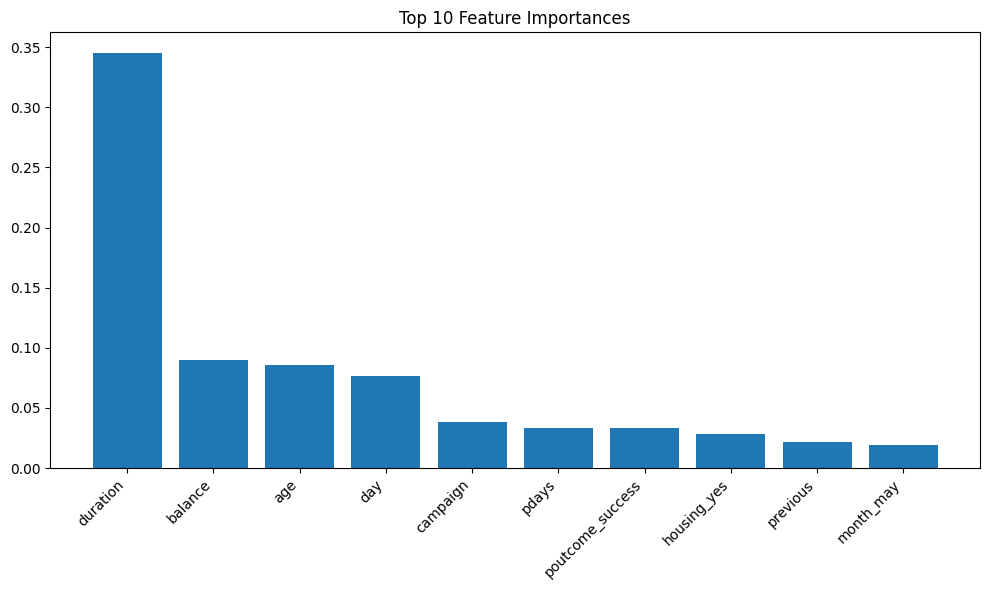

In [13]:
from sklearn.metrics import classification_report, accuracy_score
import matplotlib.pyplot as plt

# Make predictions
y_pred = rf_model.predict(X_test)

# Output performance metrics
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot top 10 feature importances
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
plt.title("Top 10 Feature Importances")
plt.bar(range(10), importances[indices[:10]], align="center")
plt.xticks(range(10), X.columns[indices[:10]], rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Step 8: Plotting an Individual Decision Tree from the Random Forest
Since a Random Forest contains many trees (100 in our case), we can visualize how a single tree works by extracting it from `rf_model.estimators_`. Because the trees can grow very deep, we will limit the depth of the visualization for readability.

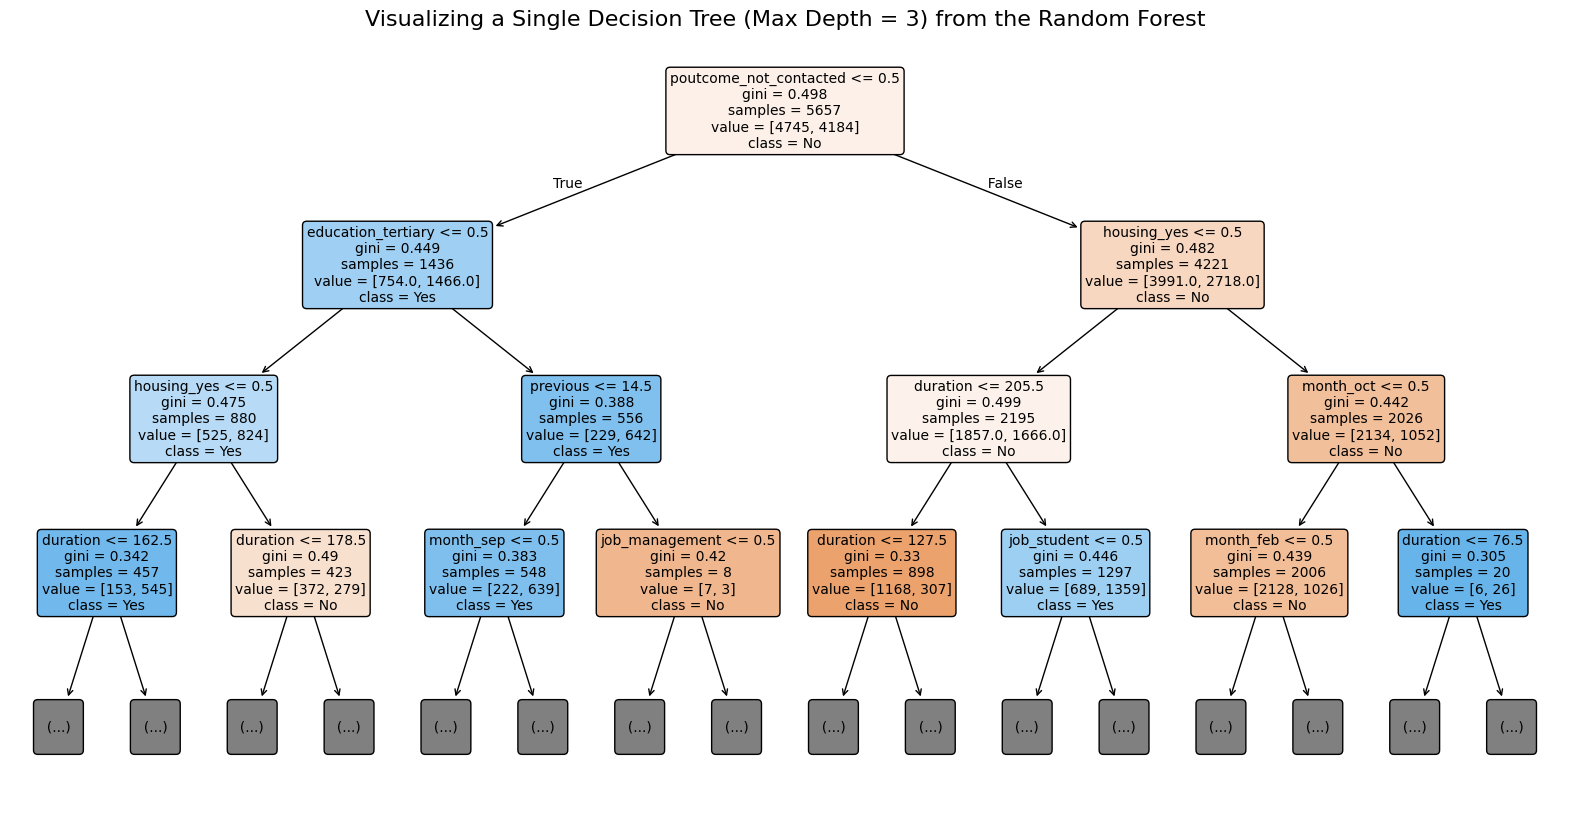

In [14]:
from sklearn.tree import plot_tree

# Extract one individual tree (e.g., the first tree at index 0)
single_tree = rf_model.estimators_[0]

# Plot the tree
plt.figure(figsize=(20, 10))
plot_tree(
    single_tree,
    max_depth=3,                  # Limit depth so the visualization is readable
    feature_names=X.columns,      # Use our encoded feature names
    class_names=['No', 'Yes'],    # Class names for deposit
    filled=True,                  # Colors nodes based on their dominant class
    rounded=True,                 # Round the corners of node boxes
    fontsize=10
)
plt.title("Visualizing a Single Decision Tree (Max Depth = 3) from the Random Forest", fontsize=16)
plt.show()